In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns

df = pd.read_csv("Fifa.csv")


print(df.duplicated().sum())



119


In [4]:
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18539 entries, 0 to 18538
Data columns (total 89 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Known As                     18539 non-null  object
 1   Full Name                    18539 non-null  object
 2   Overall                      18539 non-null  int64 
 3   Potential                    18539 non-null  int64 
 4   Value(in Euro)               18539 non-null  int64 
 5   Positions Played             18539 non-null  object
 6   Best Position                18539 non-null  object
 7   Nationality                  18539 non-null  object
 8   Image Link                   18539 non-null  object
 9   Age                          18539 non-null  int64 
 10  Height(in cm)                18539 non-null  int64 
 11  Weight(in kg)                18539 non-null  int64 
 12  TotalStats                   18539 non-null  int64 
 13  BaseStats                    18

,Known As,Full Name,Overall,Potential,Value(in Euro),Positions Played,Best Position,Nationality,Image Link,Age,...,LM Rating,CM Rating,RM Rating,LWB Rating,CDM Rating,RWB Rating,LB Rating,CB Rating,RB Rating,GK Rating
0,L. Messi,Lionel Messi,91,91,54000000,RW,CAM,Argentina,https://cdn.sofifa.net/players/158/023/23_60.png,35,...,91,88,91,67,66,67,62,53,62,22
1,K. Benzema,Karim Benzema,91,91,64000000,"CF,ST",CF,France,https://cdn.sofifa.net/players/165/153/23_60.png,34,...,89,84,89,67,67,67,63,58,63,21
2,R. Lewandowski,Robert Lewandowski,91,91,84000000,ST,ST,Poland,https://cdn.sofifa.net/players/188/545/23_60.png,33,...,86,83,86,67,69,67,64,63,64,22
3,K. De Bruyne,Kevin De Bruyne,91,91,107500000,"CM,CAM",CM,Belgium,https://cdn.sofifa.net/players/192/985/23_60.png,31,...,91,91,91,82,82,82,78,72,78,24
4,K. Mbappé,Kylian Mbappé,91,95,190500000,"ST,LW",ST,France,https://cdn.sofifa.net/players/231/747/23_60.png,23,...,92,84,92,70,66,70,66,57,66,21


In [5]:
print(df.isnull().sum())

Known As          0
Full Name         0
Overall           0
Potential         0
Value(in Euro)    0
                 ..
RWB Rating        0
LB Rating         0
CB Rating         0
RB Rating         0
GK Rating         0
Length: 89, dtype: int64


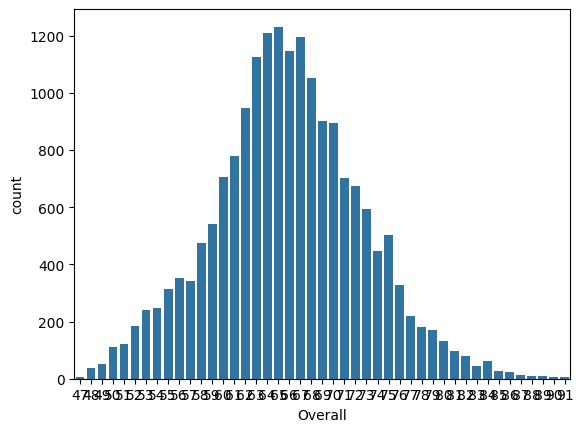

In [6]:
sns.countplot(x='Overall', data=df)
plt.show()

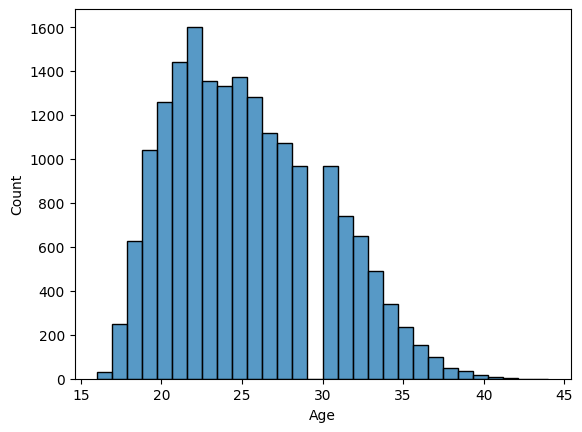

In [7]:
sns.histplot(x='Age', data=df,bins=30)
plt.show()

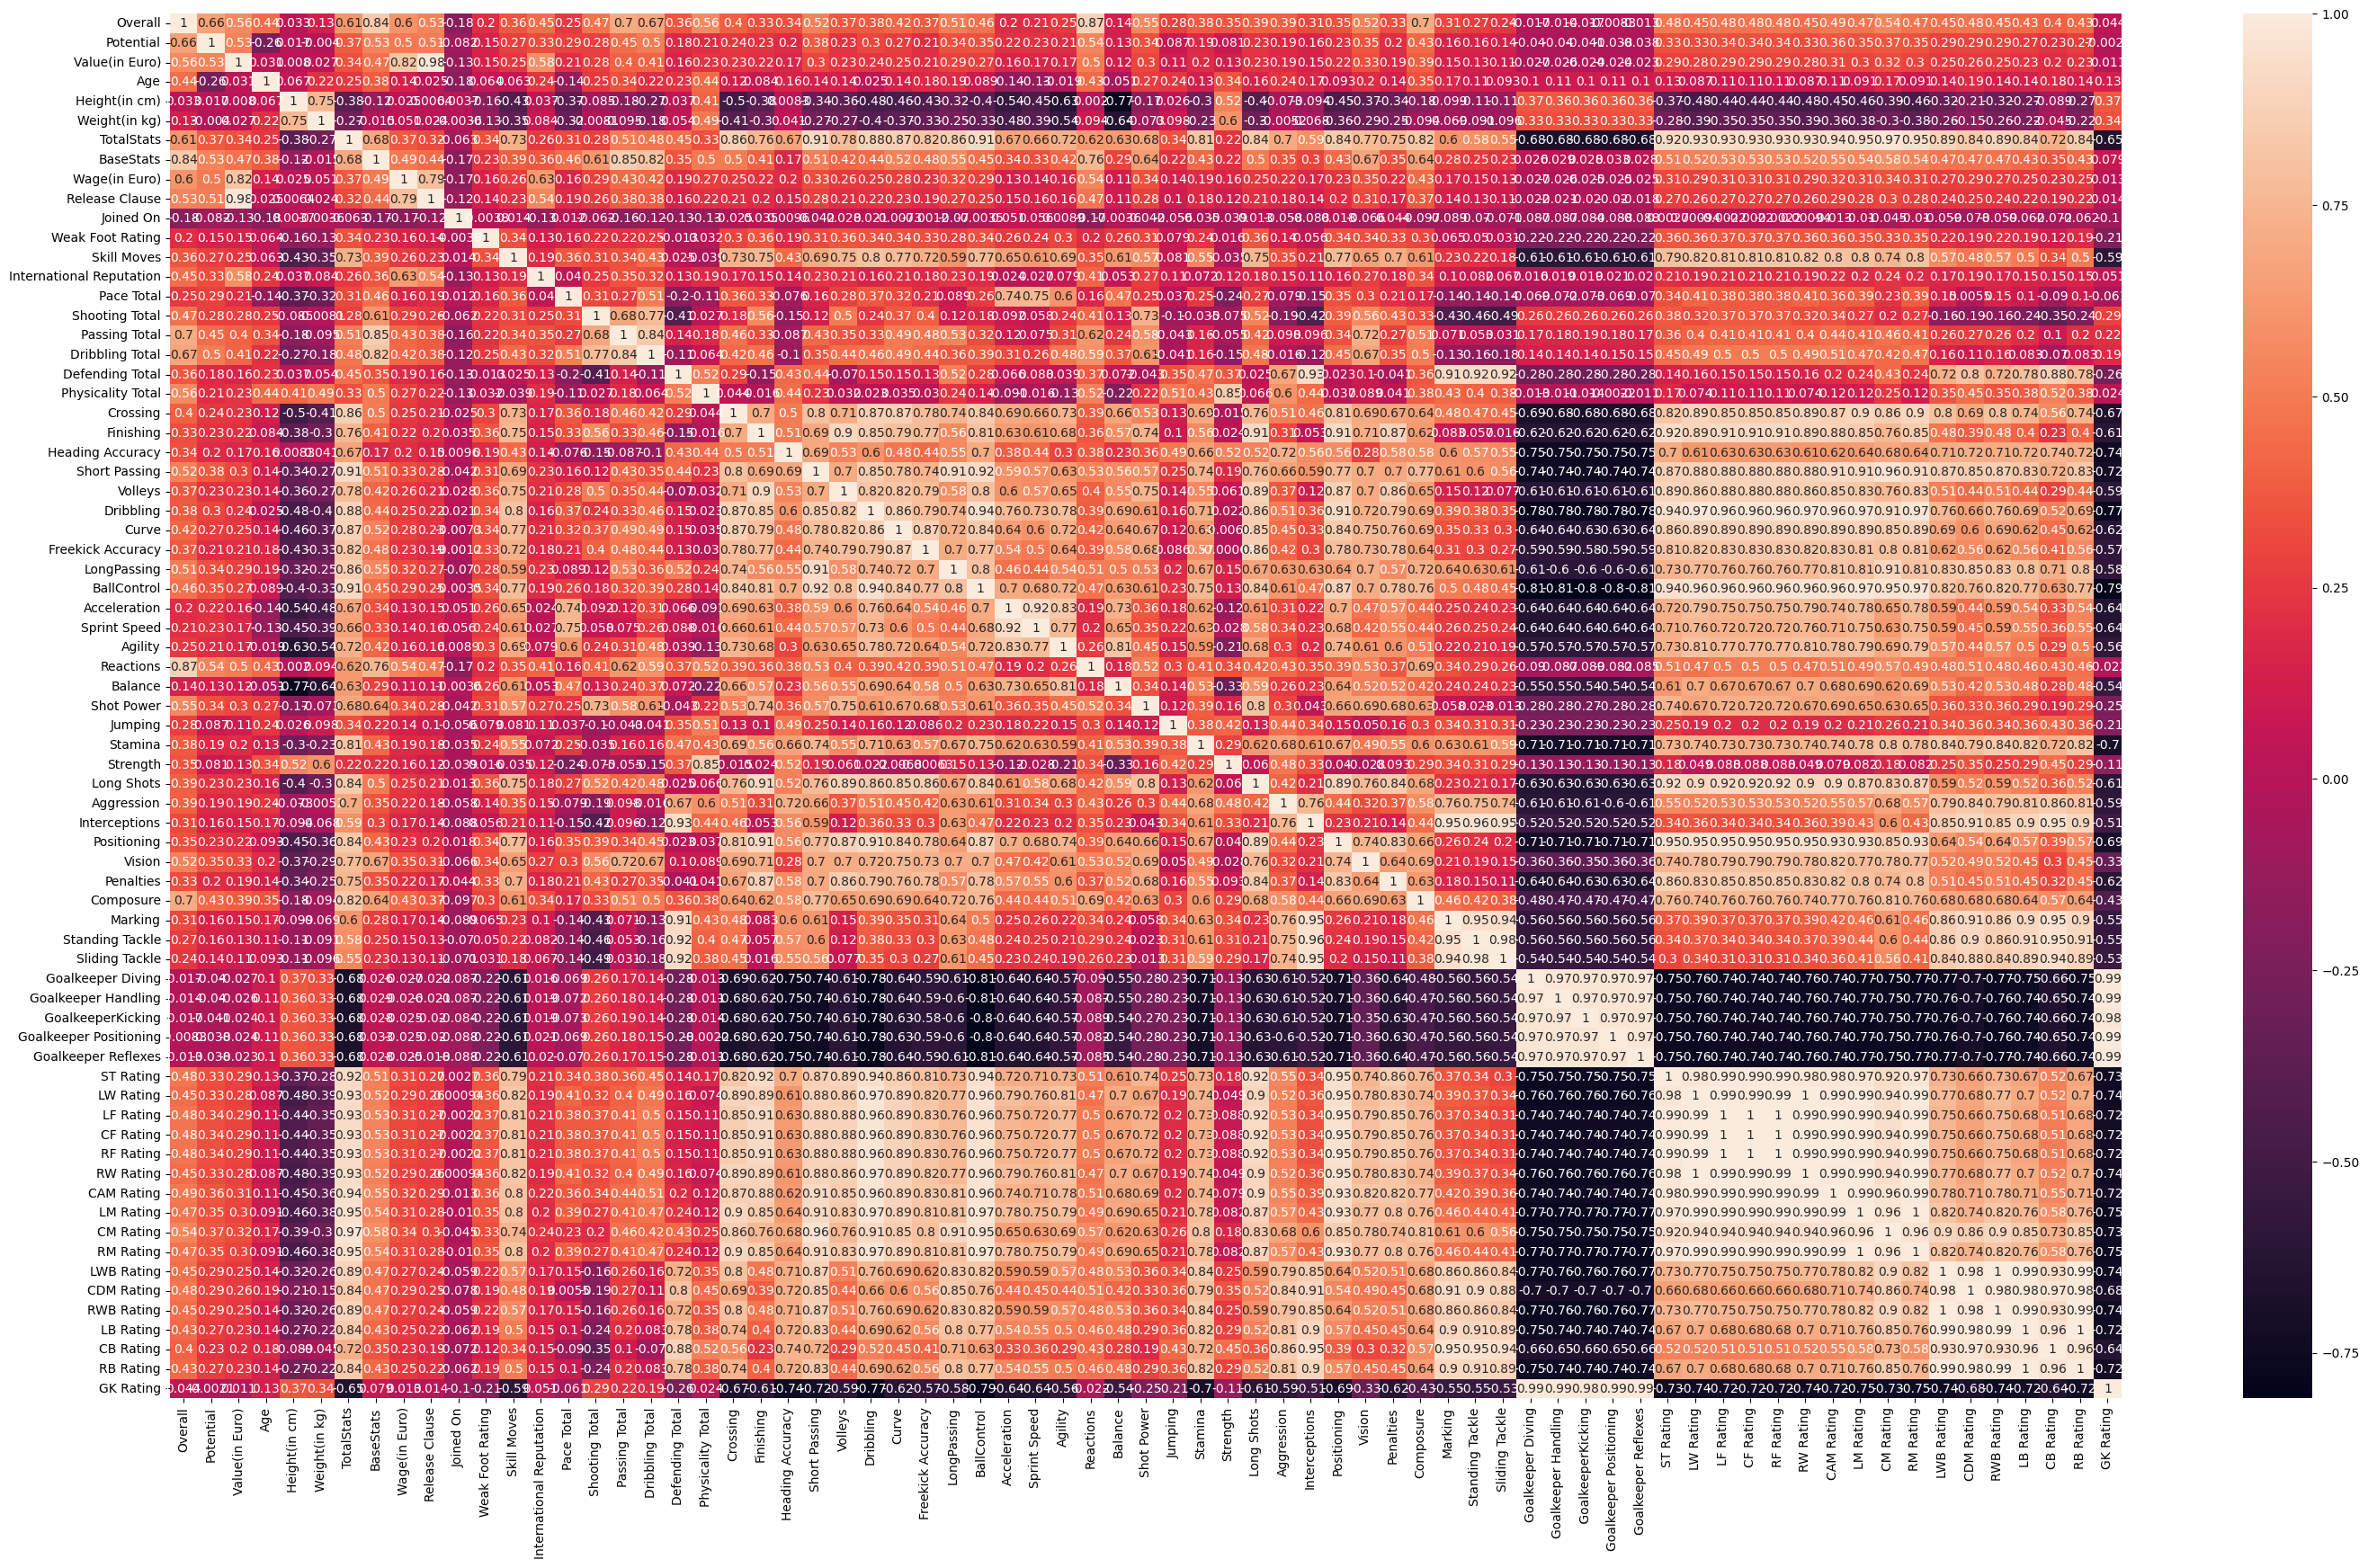

In [8]:
plt.figure(figsize=(35,20))
sns.heatmap(df.select_dtypes(include=np.number).corr(),annot=True)
plt.show()

In [9]:
# Keep only numeric columns for ML models
df_numeric = df.select_dtypes(include=['int64', 'float64'])

# Handle missing values
df_numeric = df_numeric.fillna(df_numeric.mean())

# Optional: create a classification target
df_numeric['Overall_Class'] = np.where(df_numeric['Overall'] >= 70, 1, 0)


Iteration: 0  Cost: 2148.047506394931
Iteration: 100  Cost: 303.8429236069044
Iteration: 200  Cost: 56.75699323340113
Iteration: 300  Cost: 23.65250061998215
Iteration: 400  Cost: 19.21717146329842
Iteration: 500  Cost: 18.622927504997914
Iteration: 600  Cost: 18.54331089267851
Iteration: 700  Cost: 18.53264388484667
Iteration: 800  Cost: 18.53121472260565
Iteration: 900  Cost: 18.531023243913282

Final theta0: 65.84919872716179
Final theta1: 3.00274552170602


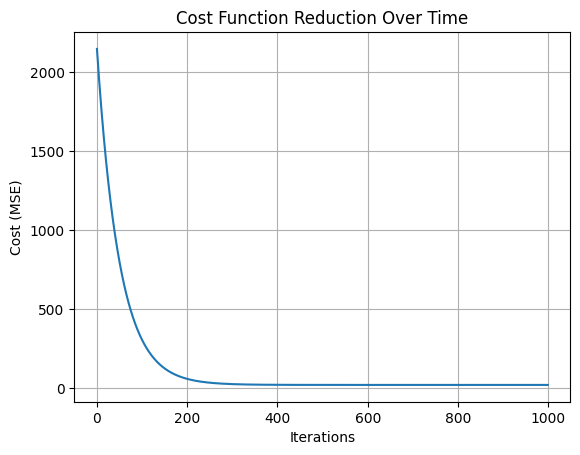


Predicted Overall for Age=30 is: 68.88


In [11]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


X = df['Age'].values
Y = df['Overall'].values

# Convert to numpy arrays
X = X.astype(float)
Y = Y.astype(float)

# Normalize feature (important)
X_mean = np.mean(X)
X_std = np.std(X)
X_norm = (X - X_mean) / X_std



def hypothesis(theta0, theta1, x):
    return theta0 + theta1 * x



def cost_function(theta0, theta1, X, Y):
    m = len(Y)
    predictions = hypothesis(theta0, theta1, X)
    cost = (1 / (2 * m)) * np.sum((predictions - Y) ** 2)
    return cost



def gradient_descent(X, Y, lr=0.01, iterations=1000):
    theta0 = 0
    theta1 = 0
    m = len(Y)
    cost_history = []

    for i in range(iterations):

        predictions = hypothesis(theta0, theta1, X)
        error = predictions - Y

        dtheta0 = (1/m) * np.sum(error)
        dtheta1 = (1/m) * np.sum(error * X)

        theta0 = theta0 - lr * dtheta0
        theta1 = theta1 - lr * dtheta1

        cost_history.append(cost_function(theta0, theta1, X, Y))

        if i % 100 == 0:
            print("Iteration:", i, " Cost:", cost_history[-1])

    print("\nFinal theta0:", theta0)
    print("Final theta1:", theta1)
    return theta0, theta1, cost_history



theta0, theta1, cost_history = gradient_descent(X_norm, Y, lr=0.01, iterations=1000)


plt.plot(cost_history)
plt.xlabel('Iterations')
plt.ylabel('Cost (MSE)')
plt.title('Cost Function Reduction Over Time')
plt.grid(True)
plt.show()


age_input = 30
age_norm = (age_input - X_mean) / X_std

predicted_overall = hypothesis(theta0, theta1, age_norm)
print(f"\nPredicted Overall for Age={age_input} is: {predicted_overall:.2f}")


Iteration 0, MSE: 4296.095012789862, MAE: 65.19352122552456
Iteration 100, MSE: 607.6858472138088, MAE: 23.862937210024743
Iteration 200, MSE: 113.51398646680227, MAE: 9.075923740812037
Iteration 300, MSE: 47.305001239964305, MAE: 5.325794570096756
Iteration 400, MSE: 38.43434292659684, MAE: 4.784442112628589
Iteration 500, MSE: 37.24585500999583, MAE: 4.731966545023351
Iteration 600, MSE: 37.086621785357025, MAE: 4.732743090560182
Iteration 700, MSE: 37.06528776969334, MAE: 4.736062396844661
Iteration 800, MSE: 37.0624294452113, MAE: 4.7377980214375786
Iteration 900, MSE: 37.062046487826564, MAE: 4.738433316170897


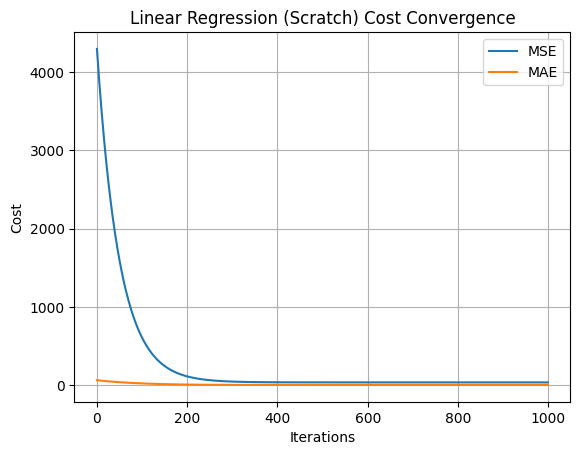

Predicted Overall for Age 30: 68.87839000239407


In [13]:

X = df_numeric["Age"].values.astype(float)
Y = df_numeric["Overall"].values.astype(float)

X_mean = X.mean()
X_std = X.std()
X_norm = (X - X_mean) / X_std

def lr_hyp(theta0, theta1, x):
    return theta0 + theta1 * x

def mse_cost(theta0, theta1, X, Y):
    return np.mean((lr_hyp(theta0, theta1, X) - Y)**2)

def mae_cost(theta0, theta1, X, Y):
    return np.mean(np.abs(lr_hyp(theta0, theta1, X) - Y))

def lr_gradient_descent(X, Y, lr=0.01, iterations=1000):
    theta0, theta1 = 0, 0
    mse_history, mae_history = [], []

    for i in range(iterations):
        pred = lr_hyp(theta0, theta1, X)
        error = pred - Y

        theta0 -= lr * np.sum(error)/len(Y)
        theta1 -= lr * np.sum(error * X)/len(Y)

        mse_history.append(mse_cost(theta0, theta1, X, Y))
        mae_history.append(mae_cost(theta0, theta1, X, Y))

        if i % 100 == 0:
            print(f"Iteration {i}, MSE: {mse_history[-1]}, MAE: {mae_history[-1]}")

    return theta0, theta1, mse_history, mae_history

theta0, theta1, mse_hist, mae_hist = lr_gradient_descent(X_norm, Y)

plt.plot(mse_hist, label="MSE")
plt.plot(mae_hist, label="MAE")
plt.title("Linear Regression (Scratch) Cost Convergence")
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.legend()
plt.grid(True)
plt.show()

age_test = 30
age_norm_test = (age_test - X_mean) / X_std
predicted_overall = lr_hyp(theta0, theta1, age_norm_test)
print("Predicted Overall for Age 30:", predicted_overall)


Iteration 0, Cost: 0.6924991485632966
Iteration 100, Cost: 0.6416026635339332
Iteration 200, Cost: 0.6104137207636117
Iteration 300, Cost: 0.5908963987037064
Iteration 400, Cost: 0.578387225033546
Iteration 500, Cost: 0.5701852213705033
Iteration 600, Cost: 0.5646975370139239
Iteration 700, Cost: 0.5609613052522874
Iteration 800, Cost: 0.5583794077500497
Iteration 900, Cost: 0.5565725244538824


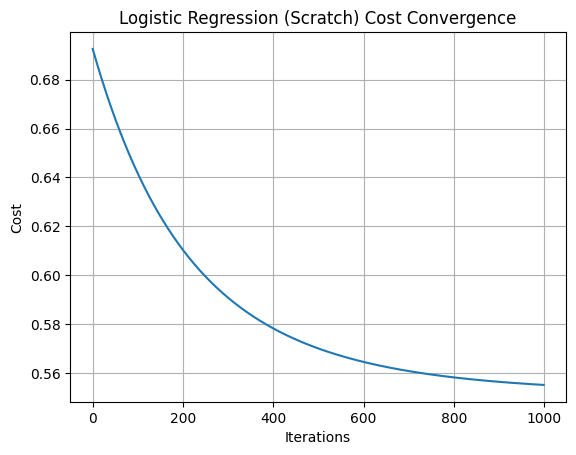

Predicted Class for Age 30: 0


In [15]:

X = df_numeric["Age"].values.astype(float)
y = np.where(df_numeric["Overall"] >= 70, 1, 0)

X_mean = X.mean()
X_std = X.std()

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_hyp(theta0, theta1, x):
    return sigmoid(theta0 + theta1 * x)

def log_cost(theta0, theta1, X, y):
    h = log_hyp(theta0, theta1, X)
    return -np.mean(y*np.log(h + 1e-8) + (1-y)*np.log(1-h + 1e-8))

def log_gradient_descent(X, y, lr=0.01, iterations=1000):
    theta0, theta1 = 0, 0
    cost_history = []

    for i in range(iterations):
        h = log_hyp(theta0, theta1, X)
        error = h - y

        theta0 -= lr * np.sum(error)/len(y)
        theta1 -= lr * np.sum(error * X)/len(y)

        cost_history.append(log_cost(theta0, theta1, X, y))

        if i % 100 == 0:
            print(f"Iteration {i}, Cost: {cost_history[-1]}")

    return theta0, theta1, cost_history

theta0, theta1, cost_hist = log_gradient_descent(X_norm, y)

plt.plot(cost_hist)
plt.title("Logistic Regression (Scratch) Cost Convergence")
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.grid(True)
plt.show()

age_test = 30
age_norm_test = (age_test - X_mean) / X_std
pred_class = 1 if log_hyp(theta0, theta1, age_norm_test) >= 0.5 else 0
print("Predicted Class for Age 30:", pred_class)


In [26]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

y_reg = df_numeric["Overall"]
X_reg = df_numeric.drop(columns=["Overall"])

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=42
)

scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

print("Regression data ready.")


Regression data ready.


In [19]:
from sklearn.model_selection import train_test_split

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=42)


In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_reg_scaled = scaler.fit_transform(X_train_reg)
X_test_reg_scaled = scaler.transform(X_test_reg)


In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

lin_reg = LinearRegression()
lin_reg.fit(X_train_reg_scaled, y_train_reg)

y_pred_lin = lin_reg.predict(X_test_reg_scaled)

mse_lin = mean_squared_error(y_test_reg, y_pred_lin)
r2_lin = r2_score(y_test_reg, y_pred_lin)

print("===== LINEAR REGRESSION RESULTS =====")
print("MSE:", mse_lin)
print("R2 Score:", r2_lin)


===== LINEAR REGRESSION RESULTS =====
MSE: 2.3619874906277496
R2 Score: 0.9483728978091394


In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

lr = LinearRegression()
lr.fit(X_train_reg_scaled, y_train_reg)

y_pred_lr = lr.predict(X_test_reg_scaled)

print("Linear Regression MSE:", mean_squared_error(y_test_reg, y_pred_lr))
print("Linear Regression R2:", r2_score(y_test_reg, y_pred_lr))


Linear Regression MSE: 2.3619874906277496
Linear Regression R2: 0.9483728978091394


In [22]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=1.0)
ridge.fit(X_train_reg_scaled, y_train_reg)

y_pred_ridge = ridge.predict(X_test_reg_scaled)

print("Ridge MSE:", mean_squared_error(y_test_reg, y_pred_ridge))
print("Ridge R2:", r2_score(y_test_reg, y_pred_ridge))


Ridge MSE: 2.3620894392799427
Ridge R2: 0.948370669468174


In [23]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.01, max_iter=5000)
lasso.fit(X_train_reg_scaled, y_train_reg)

y_pred_lasso = lasso.predict(X_test_reg_scaled)

print("Lasso MSE:", mean_squared_error(y_test_reg, y_pred_lasso))
print("Lasso R2:", r2_score(y_test_reg, y_pred_lasso))


Lasso MSE: 2.487696283206558
Lasso R2: 0.94562521997151


In [24]:
from sklearn.svm import SVR

svr = SVR(kernel='linear')
svr.fit(X_train_reg_scaled, y_train_reg)

y_pred_svr = svr.predict(X_test_reg_scaled)

print("SVR MSE:", mean_squared_error(y_test_reg, y_pred_svr))
print("SVR R2:", r2_score(y_test_reg, y_pred_svr))


SVR MSE: 2.3668001930754596
SVR R2: 0.9482677042456391


In [25]:
from sklearn.neural_network import MLPRegressor

mlp_reg = MLPRegressor(hidden_layer_sizes=(64,32),
                       activation='relu',
                       solver='adam',
                       max_iter=2000,
                       random_state=42)

mlp_reg.fit(X_train_reg_scaled, y_train_reg)

y_pred_mlp_reg = mlp_reg.predict(X_test_reg_scaled)

print("MLP Regressor MSE:", mean_squared_error(y_test_reg, y_pred_mlp_reg))
print("MLP Regressor R2:", r2_score(y_test_reg, y_pred_mlp_reg))


MLP Regressor MSE: 0.42825997708089597
MLP Regressor R2: 0.9906393146920796


In [30]:
# ===================================================
# CELL 14 — Classification Data Prep & Scaling
# ===================================================
df_numeric['Overall_Class'] = np.where(df_numeric['Overall'] >= 70, 1, 0)

X_clf = df_numeric.drop(columns=['Overall', 'Overall_Class'])
y_clf = df_numeric['Overall_Class']

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.3, random_state=42
)

scaler_clf = StandardScaler()
X_train_clf_scaled = scaler_clf.fit_transform(X_train_clf)
X_test_clf_scaled = scaler_clf.transform(X_test_clf)

print("Classification data ready.")


Classification data ready.


In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

log_model = LogisticRegression(max_iter=5000)
log_model.fit(X_train_clf_scaled, y_train_clf)

y_pred_log = log_model.predict(X_test_clf_scaled)

accuracy = accuracy_score(y_test_clf, y_pred_log)
precision = precision_score(y_test_clf, y_pred_log)
recall = recall_score(y_test_clf, y_pred_log)
f1 = f1_score(y_test_clf, y_pred_log)

print("===== LOGISTIC REGRESSION RESULTS =====")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)


===== LOGISTIC REGRESSION RESULTS =====
Accuracy: 0.9582883854728514
Precision: 0.9369189907038512
Recall: 0.911498708010336
F1 Score: 0.9240340537000655


In [32]:
from sklearn.model_selection import train_test_split

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.3, random_state=42)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_clf = StandardScaler()
X_train_clf_scaled = scaler_clf.fit_transform(X_train_clf)
X_test_clf_scaled = scaler_clf.transform(X_test_clf)


In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score

log_clf = LogisticRegression(max_iter=5000)
log_clf.fit(X_train_clf_scaled, y_train_clf)

y_pred_log = log_clf.predict(X_test_clf_scaled)

print("Logistic Regression Accuracy:", accuracy_score(y_test_clf, y_pred_log))
print("Precision:", precision_score(y_test_clf, y_pred_log))
print("Recall:", recall_score(y_test_clf, y_pred_log))


Logistic Regression Accuracy: 0.9582883854728514
Precision: 0.9369189907038512
Recall: 0.911498708010336


In [33]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train_clf_scaled, y_train_clf)

y_pred_nb = nb.predict(X_test_clf_scaled)

print("Naive Bayes Accuracy:", accuracy_score(y_test_clf, y_pred_nb))
print("Precision:", precision_score(y_test_clf, y_pred_nb))
print("Recall:", recall_score(y_test_clf, y_pred_nb))


Naive Bayes Accuracy: 0.8829557713052859
Precision: 0.7515423443634324
Recall: 0.8656330749354005


In [34]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_clf_scaled, y_train_clf)

y_pred_knn = knn.predict(X_test_clf_scaled)

print("KNN Accuracy:", accuracy_score(y_test_clf, y_pred_knn))
print("Precision:", precision_score(y_test_clf, y_pred_knn))
print("Recall:", recall_score(y_test_clf, y_pred_knn))


KNN Accuracy: 0.9421071556993887
Precision: 0.9454941860465116
Recall: 0.8404392764857881


In [35]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()
dt.fit(X_train_clf, y_train_clf)   # Decision Tree does NOT need scaling

y_pred_dt = dt.predict(X_test_clf)

print("Decision Tree Accuracy:", accuracy_score(y_test_clf, y_pred_dt))


Decision Tree Accuracy: 0.9782452355267889


In [36]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier()
rf.fit(X_train_clf, y_train_clf)

y_pred_rf = rf.predict(X_test_clf)

print("Random Forest Accuracy:", accuracy_score(y_test_clf, y_pred_rf))


Random Forest Accuracy: 0.9897518878101402


In [37]:
from sklearn.svm import SVC

svc = SVC(kernel='linear')
svc.fit(X_train_clf_scaled, y_train_clf)

y_pred_svc = svc.predict(X_test_clf_scaled)

print("SVM Accuracy:", accuracy_score(y_test_clf, y_pred_svc))
print("Precision:", precision_score(y_test_clf, y_pred_svc))
print("Recall:", recall_score(y_test_clf, y_pred_svc))


SVM Accuracy: 0.9600862998921251
Precision: 0.9390728476821192
Recall: 0.9160206718346253


In [38]:
from sklearn.neural_network import MLPClassifier

mlp_clf = MLPClassifier(hidden_layer_sizes=(32,16),
                        activation='relu',
                        solver='adam',
                        max_iter=2000)

mlp_clf.fit(X_train_clf_scaled, y_train_clf)

y_pred_mlp_clf = mlp_clf.predict(X_test_clf_scaled)

print("MLP Classifier Accuracy:", accuracy_score(y_test_clf, y_pred_mlp_clf))


MLP Classifier Accuracy: 0.9805825242718447


In [39]:


from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# PCA on scaled regression features
pca_reg = PCA(n_components=10)
X_train_reg_pca = pca_reg.fit_transform(X_train_reg_scaled)
X_test_reg_pca = pca_reg.transform(X_test_reg_scaled)

# Full Model
model_full = LinearRegression()
model_full.fit(X_train_reg_scaled, y_train_reg)
y_pred_full = model_full.predict(X_test_reg_scaled)

r2_full = r2_score(y_test_reg, y_pred_full)
mae_full = mean_absolute_error(y_test_reg, y_pred_full)

# PCA Model
model_pca = LinearRegression()
model_pca.fit(X_train_reg_pca, y_train_reg)
y_pred_pca = model_pca.predict(X_test_reg_pca)

r2_pca = r2_score(y_test_reg, y_pred_pca)
mae_pca = mean_absolute_error(y_test_reg, y_pred_pca)

# Comparison Output
print("\n===== PCA vs FULL REGRESSION COMPARISON =====")
print(f"Full R2 : {r2_full:.4f}")
print(f"PCA R2  : {r2_pca:.4f}")
print("---------------------------")
print(f"Full MAE: {mae_full:.4f}")
print(f"PCA MAE : {mae_pca:.4f}")



===== PCA vs FULL REGRESSION COMPARISON =====
Full R2 : 0.9484
PCA R2  : 0.8784
---------------------------
Full MAE: 1.1967
PCA MAE : 1.8628


In [40]:


from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score

# PCA Transformation (classification)
pca_clf = PCA(n_components=10)
X_train_clf_pca = pca_clf.fit_transform(X_train_clf_scaled)
X_test_clf_pca = pca_clf.transform(X_test_clf_scaled)

# Full Model
log_full = LogisticRegression(max_iter=5000)
log_full.fit(X_train_clf_scaled, y_train_clf)
y_pred_full = log_full.predict(X_test_clf_scaled)

acc_full = accuracy_score(y_test_clf, y_pred_full)
prec_full = precision_score(y_test_clf, y_pred_full)
rec_full = recall_score(y_test_clf, y_pred_full)

# PCA Model
log_pca = LogisticRegression(max_iter=5000)
log_pca.fit(X_train_clf_pca, y_train_clf)
y_pred_pca = log_pca.predict(X_test_clf_pca)

acc_pca = accuracy_score(y_test_clf, y_pred_pca)
prec_pca = precision_score(y_test_clf, y_pred_pca)
rec_pca = recall_score(y_test_clf, y_pred_pca)

# Comparison Output
print("\n===== PCA vs FULL CLASSIFICATION COMPARISON =====")
print(f"Full Accuracy : {acc_full:.4f}")
print(f"PCA Accuracy  : {acc_pca:.4f}")
print("---------------------------")
print(f"Full Precision: {prec_full:.4f}")
print(f"PCA Precision : {prec_pca:.4f}")
print("---------------------------")
print(f"Full Recall   : {rec_full:.4f}")
print(f"PCA Recall    : {rec_pca:.4f}")



===== PCA vs FULL CLASSIFICATION COMPARISON =====
Full Accuracy : 0.9583
PCA Accuracy  : 0.9383
---------------------------
Full Precision: 0.9369
PCA Precision : 0.9175
---------------------------
Full Recall   : 0.9115
PCA Recall    : 0.8553


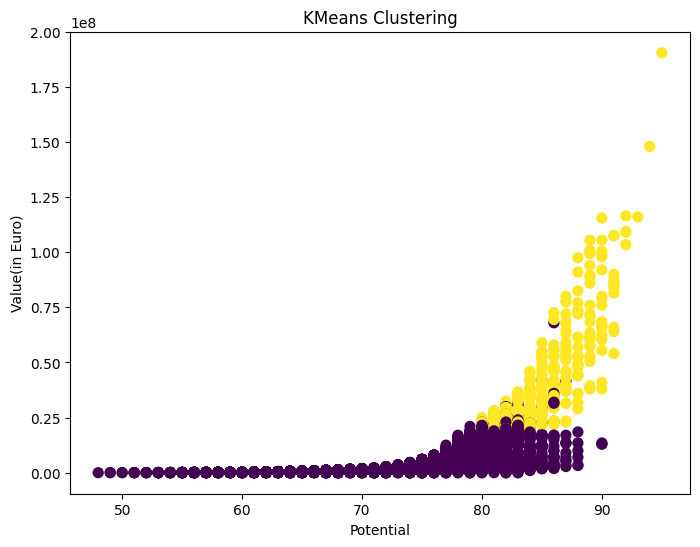

In [41]:

from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_labels = kmeans.fit_predict(X_clf)

plt.figure(figsize=(8,6))
plt.scatter(X_clf.iloc[:,0], X_clf.iloc[:,1], c=kmeans_labels, cmap='viridis', s=50)
plt.title("KMeans Clustering")
plt.xlabel(X_clf.columns[0])
plt.ylabel(X_clf.columns[1])
plt.show()


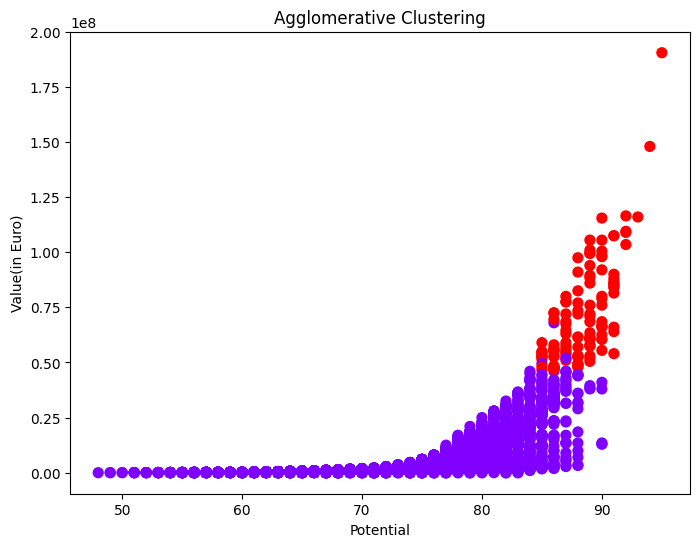

In [42]:

from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=2)
agg_labels = agg.fit_predict(X_clf)

plt.figure(figsize=(8,6))
plt.scatter(X_clf.iloc[:,0], X_clf.iloc[:,1], c=agg_labels, cmap='rainbow', s=50)
plt.title("Agglomerative Clustering")
plt.xlabel(X_clf.columns[0])
plt.ylabel(X_clf.columns[1])
plt.show()


In [43]:
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier()
ada.fit(X_train_clf, y_train_clf)

y_pred_ada = ada.predict(X_test_clf)

print("AdaBoost Accuracy:", accuracy_score(y_test_clf, y_pred_ada))


AdaBoost Accuracy: 0.9866954332973751


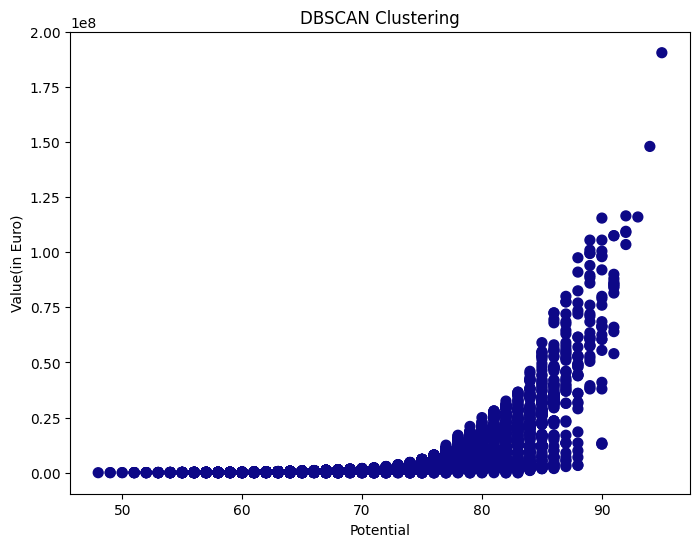

In [44]:

from sklearn.cluster import DBSCAN

db = DBSCAN(eps=3, min_samples=5)
db_labels = db.fit_predict(X_clf)

plt.figure(figsize=(8,6))
plt.scatter(X_clf.iloc[:,0], X_clf.iloc[:,1], c=db_labels, cmap='plasma', s=50)
plt.title("DBSCAN Clustering")
plt.xlabel(X_clf.columns[0])
plt.ylabel(X_clf.columns[1])
plt.show()


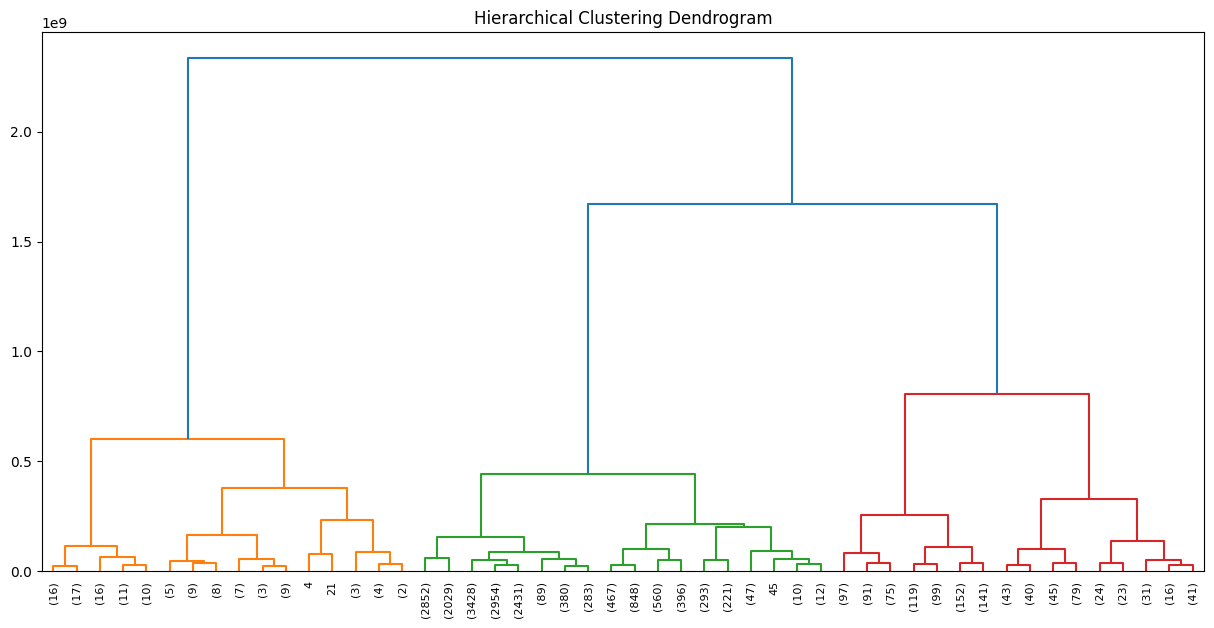

In [45]:

import scipy.cluster.hierarchy as sch

plt.figure(figsize=(15, 7))
linkage = sch.linkage(X_clf, method='ward')
sch.dendrogram(linkage, truncate_mode='lastp', p=50)
plt.title("Hierarchical Clustering Dendrogram")
plt.show()
